# Дополнительные расчёты к статье: метрики качества прогноза

Этот ноутбук дополняет основной ноутбук `repeat_visit_risk_prediction.ipynb`. Модели, разбиения и параметры — те же самые.
Здесь считаются только величины, которые нужны для раздела статьи о метриках:

- матрица ошибок при пороге 0,5 в пересчёте на 100 заказ-нарядов;
- метрики «прогноза без модели» — точка отсчёта для Accuracy, ROC-AUC и Brier;
- точки ROC-кривой для порогов 0,20, 0,35, 0,50 и сама ROC-кривая (рисунок 4 статьи);
- проверка смысла ROC-AUC через пары «вернулся / не вернулся»;
- согласованность прогнозных вероятностей с фактической долей возвратов (калибровка).

Данные: `data/service_repeat_visit_dataset.csv` — 3 000 закрытых заказ-нарядов из постановки задачи.

## 1. Подключение библиотек

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

## 2. Загрузка данных и признаки

Те же шесть признаков, что и в основном ноутбуке. Целевой признак — `repeat_visit_within_30d`.

In [2]:
df = pd.read_csv("data/service_repeat_visit_dataset.csv")

features = [
    "repair_complexity_score",
    "labor_hours",
    "num_parts_installed",
    "diagnostic_accuracy_flag",
    "technician_experience_years",
    "vehicle_brand_segment",
]
target = "repeat_visit_within_30d"

X = df[features]
y = df[target]
print("Заказ-нарядов:", len(df), "| доля возвратов:", round(y.mean(), 3))

Заказ-нарядов: 3000 | доля возвратов: 0.338


## 3. Прогноз без модели — точка отсчёта

Чтобы понимать, много это или мало, каждую метрику сравниваем с самым простым прогнозом, который не требует модели:

- **Accuracy:** прогноз «никто не вернётся» верен для всех невернувшихся клиентов, то есть в 66 % случаев;
- **ROC-AUC:** случайная сортировка заказ-нарядов даёт 0,5;
- **Brier:** если каждому заказ-наряду приписать одну и ту же вероятность, равную средней доле возвратов, ошибка равна p·(1 − p).

In [3]:
p_base = y.mean()

baseline = pd.DataFrame({
    "метрика": ["Accuracy", "ROC-AUC", "Brier"],
    "прогноз без модели": [1 - p_base, 0.5, p_base * (1 - p_base)],
})
display(baseline.round(4))

,метрика,прогноз без модели
0,Accuracy,0.6620
1,ROC-AUC,0.5000
2,Brier,0.2238


## 4. Цикл из 100 запусков

Разбиения и модели — точно как в основном ноутбуке (`random_state = 0…99`, 80/20, стратификация,
масштабирование только по обучающей части). В каждом запуске сохраняем:

- матрицу ошибок при пороге 0,5 для способов А и B;
- ROC-кривую каждого способа на общей сетке значений доли ложных тревог (0, 0,01, …, 1), чтобы потом усреднить;
- долю пойманных возвратов и долю ложных тревог способа А при порогах 0,20, 0,35, 0,50;
- вероятности способа А на тестовой части — для проверки калибровки.

In [4]:
grid = np.linspace(0, 1, 101)       # общая сетка доли ложных тревог для усреднения ROC-кривых
roc_A, roc_B = [], []
cm_rows = []
roc_points = []
pooled = []

for seed in range(100):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed)

    # Способ А: логистическая регрессия, масштаб — только по обучающей части
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    model_A = LogisticRegression(max_iter=1000).fit(X_train_scaled, y_train)
    prob_A = model_A.predict_proba(X_test_scaled)[:, 1]

    # Способ B: случайный лес
    model_B = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=seed).fit(X_train, y_train)
    prob_B = model_B.predict_proba(X_test)[:, 1]

    for name, prob, store in [("А", prob_A, roc_A), ("B", prob_B, roc_B)]:
        fpr, tpr, _ = roc_curve(y_test, prob)
        curve = np.interp(grid, fpr, tpr)
        curve[0] = 0                  # кривая начинается в точке (0; 0)
        store.append(curve)
        tn, fp, fn, tp = confusion_matrix(y_test, (prob >= 0.5).astype(int)).ravel()
        cm_rows.append({"способ": name, "TP": tp, "FP": fp, "FN": fn, "TN": tn})

    returned = y_test.values == 1
    for t in [0.20, 0.35, 0.50]:
        alarm = prob_A >= t
        roc_points.append({
            "порог": t,
            "поймано возвратов (TPR), %": (alarm & returned).sum() / returned.sum() * 100,
            "ложных тревог (FPR), %": (alarm & ~returned).sum() / (~returned).sum() * 100,
        })

    pooled.append(pd.DataFrame({"вероятность": prob_A, "вернулся": y_test.values}))

print("Выполнено запусков:", seed + 1)

Выполнено запусков: 100


## 5. Матрица ошибок при пороге 0,5 на 100 заказ-нарядов

Тестовая часть — 600 заказ-нарядов, поэтому делим средние значения на 6.
TP — пойманный возврат, FP — ложная тревога, FN — пропущенный возврат, TN — спокойная выдача.

In [5]:
cm = pd.DataFrame(cm_rows).groupby("способ").mean().loc[["А", "B"]] / 600 * 100
display(cm.round(1))

,TP,FP,FN,TN
способ,,,,
А,25.6,5.1,8.2,61.1
B,23.3,3.4,10.5,62.8


## 6. Точки ROC-кривой способа А для трёх порогов

In [6]:
display(pd.DataFrame(roc_points).groupby("порог").mean().round(1))

,"поймано возвратов (TPR), %","ложных тревог (FPR), %"
порог,,
0.20,90.4,27.3
0.35,83.7,15.2
0.50,75.7,7.7


## 7. Смысл ROC-AUC: доля правильно упорядоченных пар

ROC-AUC равна доле пар «вернувшийся клиент — невернувшийся клиент», в которых модель дала вернувшемуся
более высокую вероятность. Проверяем это на одном запуске (`random_state = 0`): две величины должны совпасть.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
scaler = StandardScaler()
prob = LogisticRegression(max_iter=1000).fit(scaler.fit_transform(X_train), y_train).predict_proba(scaler.transform(X_test))[:, 1]

p_returned = prob[y_test.values == 1]
p_not_returned = prob[y_test.values == 0]
pairs_ok = (p_returned[:, None] > p_not_returned[None, :]).mean()

print("Пар всего:", len(p_returned) * len(p_not_returned))
print("Доля правильно упорядоченных пар:", round(pairs_ok, 4))
print("ROC-AUC:", round(roc_auc_score(y_test, prob), 4))

Пар всего: 80591
Доля правильно упорядоченных пар: 0.9263
ROC-AUC: 0.9263


## 8. Калибровка: совпадает ли прогнозная вероятность с фактической долей возвратов

Объединяем тестовые прогнозы способа А из всех 100 запусков, делим их на пять групп по величине вероятности
и в каждой группе сравниваем среднюю прогнозную вероятность с фактической долей вернувшихся клиентов.

In [8]:
pool = pd.concat(pooled)
pool["группа"] = pd.cut(pool["вероятность"], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)

calibration = pool.groupby("группа", observed=True).agg(
    доля_заказ_нарядов=("вернулся", "size"),
    прогноз=("вероятность", "mean"),
    факт=("вернулся", "mean"),
)
calibration["доля_заказ_нарядов"] = calibration["доля_заказ_нарядов"] / len(pool)
display(calibration.round(3))

,доля_заказ_нарядов,прогноз,факт
группа,,,
"(-0.001, 0.2]",0.514,0.057,0.063
"(0.2, 0.4]",0.128,0.290,0.238
"(0.4, 0.6]",0.096,0.496,0.456
"(0.6, 0.8]",0.078,0.703,0.723
"(0.8, 1.0]",0.183,0.929,0.954


## 9. Рисунок 4 статьи: ROC-кривые, усреднённые по 100 запускам

Точки на кривой способа А — пороги 0,20, 0,35 и 0,50 (средние по 100 запускам).

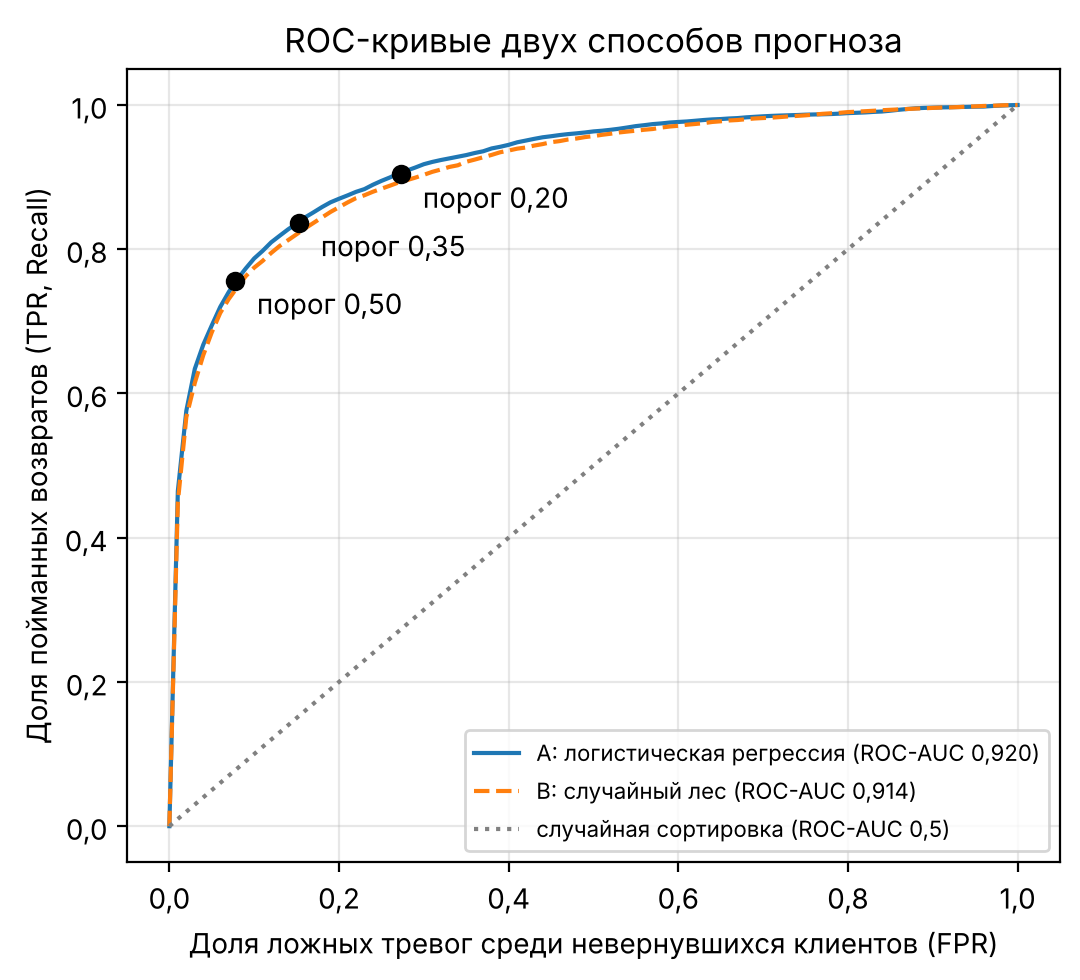

In [9]:
os.makedirs("pictures", exist_ok=True)
pts = pd.DataFrame(roc_points).groupby("порог").mean() / 100

plt.figure(figsize=(5.5, 5))
plt.plot(grid, np.mean(roc_A, axis=0), label="А: логистическая регрессия (ROC-AUC 0,920)")
plt.plot(grid, np.mean(roc_B, axis=0), "--", label="B: случайный лес (ROC-AUC 0,914)")
plt.plot([0, 1], [0, 1], ":", color="gray", label="случайная сортировка (ROC-AUC 0,5)")
plt.plot(pts["ложных тревог (FPR), %"], pts["поймано возвратов (TPR), %"], "o", color="black")
for t, row in pts.iterrows():
    plt.annotate(f"порог {t:.2f}".replace(".", ","),
                 (row["ложных тревог (FPR), %"], row["поймано возвратов (TPR), %"]),
                 textcoords="offset points", xytext=(8, -12))
plt.xlabel("Доля ложных тревог среди невернувшихся клиентов (FPR)")
plt.ylabel("Доля пойманных возвратов (TPR, Recall)")
plt.title("ROC-кривые двух способов прогноза")
ticks = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
plt.xticks(ticks, [f"{v:.1f}".replace(".", ",") for v in ticks])
plt.yticks(ticks, [f"{v:.1f}".replace(".", ",") for v in ticks])
plt.grid(alpha=0.3)
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("pictures/fig4_roc_curves.png", dpi=300)
plt.show()

## 10. Итог

Все числа раздела статьи о метриках взяты из этого ноутбука и из основного `repeat_visit_risk_prediction.ipynb`.